# Chapter 2: Why Your Mind Goes Blank

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will see that the arithmetic of 47 + 38 never changes, while the place where the middle of the work lives does. You will move steps from memory to paper, watch a new ten get its full value, check one route to a sum against another, and leave a route back after a subtraction.

**A note before you start.** The code cells are optional reading. You do not need to run or understand them: the numbers and pictures they produce are already shown right below each one. If you are curious, read the code like a recipe, one line at a time.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch

INK, TEAL, GOLD, RED, GREY, NAVY = "#172a3b", "#0f6268", "#b8860b", "#a24a33", "#6b757b", "#1f3b5c"
PALE, PICK = "#e3efee", "#f3e1da"
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.edgecolor": GREY,
                     "axes.labelcolor": INK, "text.color": INK})

def blank(ax):
    """Hide ticks and frame so a drawing looks like a drawing."""
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

def as_set(items):
    """Write a collection the way the book does: {3, 6, 9}."""
    items = list(items)
    return "{" + ", ".join(str(i) for i in items) + "}" if items else "{ }"

yn = lambda b: "yes" if b else "no"

## 1. Same arithmetic, different workspace

**The question.** If $47 + 38$ stays the same, what changes when more of its lines are written down?

**The equations from the chapter.**

$$47 + 38 \qquad\qquad 47 = 40 + 7$$

**What the symbols mean.** 47 and 38 are the starting quantities and $+$ is the operation. Writing $47 = 40 + 7$ splits 47 into four tens and seven ones. Each written line puts part of the work on the page, where you can see it instead of holding it in your head. The place-value route has five lines. We start with **all five written**.

**Try to predict first.** Once only the two expansions are written, how many middle quantities does memory still have to carry, and which ones?

In [2]:
lines = ["47 = 40 + 7", "38 = 30 + 8", "40 + 30 = 70", "7 + 8 = 15", "70 + 15 = 85"]
# the quantities each line puts on the page
line_quantities = [[40, 7], [30, 8], [70], [15], [85]]

def workspace(k):
    on_page = [q for qs in line_quantities[:k] for q in qs]
    in_mind = [q for qs in line_quantities[k:4] for q in qs]   # middle quantities not yet written
    return on_page, in_mind

k = 5
on_page, in_mind = workspace(k)
print("The arithmetic, line by line:")
print("  47 = 40 + 7")
print("  38 = 30 + 8")
print("  tens:  40 + 30 =", 40 + 30)
print("  ones:  7 + 8 =", 7 + 8)
print("  total: 70 + 15 =", 70 + 15)
print()
print(f"With {k} of the 5 lines written, the page shows {len(on_page)} quantities: {on_page}")
print("Middle quantities held in mind:", len(in_mind), in_mind if in_mind else "(none)")

The arithmetic, line by line:
  47 = 40 + 7
  38 = 30 + 8
  tens:  40 + 30 = 70
  ones:  7 + 8 = 15
  total: 70 + 15 = 85

With 5 of the 5 lines written, the page shows 7 quantities: [40, 7, 30, 8, 70, 15, 85]
Middle quantities held in mind: 0 (none)


Here is the same task with fewer lines written. The arithmetic is identical; only the load on memory changes.

In [3]:
names = {0: "head only", 2: "expansions written", 4: "expansions and sums written", 5: "every line written"}
print(f"{'Lines written':16s}{'Workspace':30s}{'Held in mind':14s}Which")
for k in [0, 2, 4, 5]:
    _, held = workspace(k)
    print(f"{k:<16d}{names[k]:30s}{len(held):<14d}{held if held else 'none'}")

Lines written   Workspace                     Held in mind  Which
0               head only                     6             [40, 7, 30, 8, 70, 15]
2               expansions written            2             [70, 15]
4               expansions and sums written   0             none
5               every line written            0             none


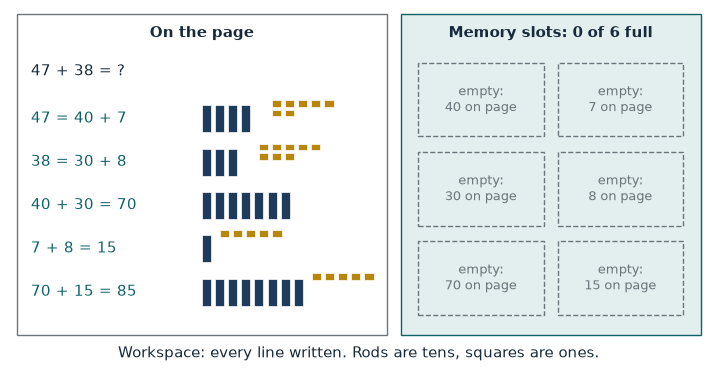

In [4]:
def token(ax, x, y, value, size=0.13):
    """A quantity as tens rods and ones squares; returns the right edge."""
    tens, ones = divmod(value, 10)
    gap = size * 1.45
    for _ in range(tens):
        ax.add_patch(Rectangle((x, y), size, 0.62 * size / 0.13 * 0.85, facecolor=NAVY, edgecolor="white", linewidth=0.5)); x += gap
    if tens and ones: x += 0.07
    for o in range(ones):
        r, c = divmod(o, 5)
        ax.add_patch(Rectangle((x + c * gap, y + 0.5 - r * gap), size, size, facecolor=GOLD, edgecolor="white", linewidth=0.5))
    return x + min(ones, 5) * gap

def workspace_figure(k):
    on_page, in_mind = workspace(k)
    middle = [40, 7, 30, 8, 70, 15]
    fig, ax = plt.subplots(figsize=(9, 4.3))
    ax.add_patch(Rectangle((0.1, 0.1), 5.3, 6.3, facecolor="white", edgecolor=GREY))
    ax.add_patch(Rectangle((5.6, 0.1), 4.3, 6.3, facecolor=PALE, edgecolor=TEAL))
    ax.text(2.75, 5.95, "On the page", ha="center", fontweight="bold")
    ax.text(7.75, 5.95, f"Memory slots: {len(in_mind)} of 6 full", ha="center", fontweight="bold")
    ax.text(0.3, 5.2, "47 + 38 = ?")
    for i, line in enumerate(lines):
        y = 4.35 - i * 0.85
        if i < k:
            ax.text(0.3, y, line, color=TEAL, va="center")
            x = 2.75
            for q in line_quantities[i]:
                x = token(ax, x, y - 0.27, q) + 0.25
        else:
            ax.text(0.3, y, "(not written)", color=GREY, va="center")
    held = list(in_mind)
    for j, q in enumerate(middle):
        col, row = j % 2, j // 2
        x0, y0 = 5.85 + col * 2.0, 4.0 - row * 1.75
        if q in held:
            held.remove(q)
            ax.add_patch(Rectangle((x0, y0), 1.8, 1.45, facecolor="white", edgecolor=RED, linewidth=1.6))
            ax.text(x0 + 0.9, y0 + 0.72, f"holding {q}", ha="center", va="center", color=RED)
        else:
            ax.add_patch(Rectangle((x0, y0), 1.8, 1.45, facecolor="none", edgecolor=GREY, linestyle="dashed"))
            ax.text(x0 + 0.9, y0 + 0.72, f"empty:\n{q} on page", ha="center", va="center", color=GREY, fontsize=9.5)
    ax.set_xlim(0, 10); ax.set_ylim(0, 6.5)
    blank(ax)
    ax.set_xlabel(f"Workspace: {names[k]}. Rods are tens, squares are ones.")
    plt.show()

workspace_figure(5)

**What this shows.** With every line written, the page holds all the middle results, so memory only has to follow the lines: $40 + 30 = 70$, $7 + 8 = 15$, and $70 + 15 = 85$. Slide back to "head only" and memory must carry six middle quantities at once. Same arithmetic, heavier load. When a thread goes missing mid-calculation, that is a statement about the workspace, not about you.

**Where it stops working.** The count of held quantities follows only this place-value route; another route would hold different quantities. It describes the task, not the person doing it.

## 2. A tens-and-ones record

**The question.** When the ones add up past nine, where does the extra ten go?

**The equation from the chapter.**

$$70 + 10 + 4 = 84$$

**What the symbols mean.** Each rod is one ten and each small square is one. In $56 + 28$: 70 is the tens total, 10 is the *new ten* made from the ones, and 4 is the ones left over. We start with $56 + 28$.

**Try to predict first.** For $41 + 37$, will a new ten appear? Add the ones before you look.

In [5]:
def tens_ones(a, b):
    at, ao = divmod(a, 10)
    bt, bo = divmod(b, 10)
    tens_sum = (at + bt) * 10
    ones_sum = ao + bo
    return at, ao, bt, bo, tens_sum, ones_sum

a, b = 56, 28
at, ao, bt, bo, tens_sum, ones_sum = tens_ones(a, b)
print(f"{a} = {at*10} + {ao}")
print(f"{b} = {bt*10} + {bo}")
print(f"Tens: {at*10} + {bt*10} = {tens_sum}")
print(f"Ones: {ao} + {bo} = {ones_sum}")
if ones_sum >= 10:
    left = ones_sum - 10
    print(f"{ones_sum} is one ten and {left} ones, so the record is {tens_sum} + 10 + {left} = {tens_sum + 10 + left}")
print(f"Check: {a} + {b} = {a + b}")

56 = 50 + 6
28 = 20 + 8
Tens: 50 + 20 = 70
Ones: 6 + 8 = 14
14 is one ten and 4 ones, so the record is 70 + 10 + 4 = 84
Check: 56 + 28 = 84


In [6]:
print(f"{'Sum':10s}{'Tens':14s}{'Ones':10s}{'New ten?':10s}Total")
for a, b in [(56, 28), (47, 38), (57, 26), (41, 37)]:
    at, ao, bt, bo, ts, os_ = tens_ones(a, b)
    print(f"{a} + {b:<5d}{at*10} + {bt*10} = {ts:<4d}{ao} + {bo} = {os_:<4d}{'yes' if os_ >= 10 else 'none':10s}{a + b}")

Sum       Tens          Ones      New ten?  Total
56 + 28   50 + 20 = 70  6 + 8 = 14  yes       84
47 + 38   40 + 30 = 70  7 + 8 = 15  yes       85
57 + 26   50 + 20 = 70  7 + 6 = 13  yes       83
41 + 37   40 + 30 = 70  1 + 7 = 8   none      78


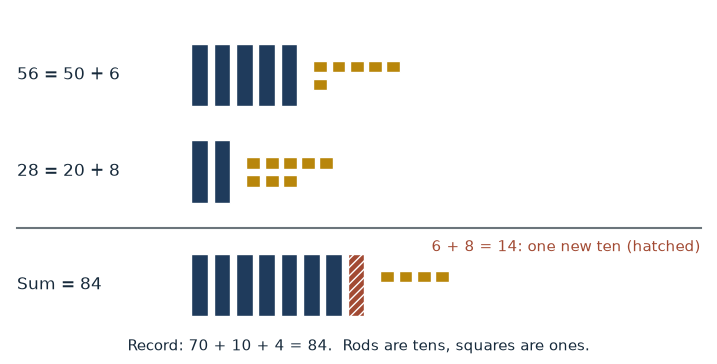

In [7]:
def blocks(ax, x0, y, tens, ones, new_ten=False):
    x = x0
    for _ in range(tens):
        ax.add_patch(Rectangle((x, y), 0.24, 1.1, facecolor=NAVY, edgecolor="white")); x += 0.32
    if new_ten:
        ax.add_patch(Rectangle((x, y), 0.24, 1.1, facecolor=RED, edgecolor="white", hatch="////")); x += 0.32
    x += 0.15
    for o in range(ones):
        r, c = divmod(o, 5)
        ax.add_patch(Rectangle((x + c * 0.26, y + 0.6 - r * 0.32), 0.2, 0.2, facecolor=GOLD, edgecolor="white"))

a, b = 56, 28
at, ao, bt, bo, ts, os_ = tens_ones(a, b)
carry = os_ >= 10
fig, ax = plt.subplots(figsize=(9, 4.2))
rows = [(4.3, f"{a} = {at*10} + {ao}", at, ao, False),
        (2.6, f"{b} = {bt*10} + {bo}", bt, bo, False),
        (0.6, f"Sum = {a + b}", at + bt, os_ - 10 if carry else os_, carry)]
for y, text, t, o, nt in rows:
    ax.text(0.1, y + 0.55, text, fontsize=12, va="center")
    blocks(ax, 2.6, y, t, o, nt)
ax.plot([0.1, 9.9], [2.15, 2.15], color=GREY)
ax.text(9.9, 1.95, f"{ao} + {bo} = {os_}: one new ten (hatched)", ha="right", va="top", color=RED)
ax.set_xlim(0, 10); ax.set_ylim(0.3, 6.0)
blank(ax)
ax.set_xlabel(f"Record: {ts} + 10 + {os_ - 10} = {a + b}.  Rods are tens, squares are ones.")
plt.show()

**What this shows.** Tens join tens and ones join ones. When the ones reach ten or more, ten of them regroup into one new rod, and that rod keeps its full value of 10 in the record: $50 + 20 = 70$, then $6 + 8 = 14$, which is one ten and 4 ones, so $70 + 10 + 4 = 84$. When you carry a "1" in a stacked sum, say it to yourself as "ten." Writing its full value keeps it from disappearing. For $41 + 37$ the ones make $1 + 7 = 8$, so no new ten appears.

**Where it stops working.** These are two-digit whole numbers added by place value. With three-digit numbers a hundreds column joins the record.

## 3. Two routes to the same sum

**The question.** Can a route that overshoots on purpose still land on the right answer?

**The equations from the chapter.**

$$47 + 38 = 47 + 40 - 2 \qquad\qquad 70 + 15 = 85$$

**What the symbols mean.** $47 + 40 - 2$ replaces 38 with the nearby 40, then subtracts the extra 2. $70 + 15$ is the place-value record: tens total plus ones total. We start with $47 + 38$ by *compensation* (jump to a round number, then correct).

**Try to predict first.** For $36 + 49$ by compensation, which round number will you add, and what will the correction be?

In [8]:
def add_routes(a, b):
    bt, bo = (b // 10) * 10, b % 10
    up = (b // 10 + 1) * 10          # next ten above b
    extra = up - b
    return bt, bo, up, extra

a, b = 47, 38
bt, bo, up, extra = add_routes(a, b)
print("Route 1, compensation:")
print(f"  {b} is close to {up}, and {up} - {b} = {extra}")
print(f"  {a} + {b} = {a} + {up} - {extra}")
print(f"  {a} + {up} = {a + up}   (this is the middle stop)")
print(f"  {a + up} - {extra} = {a + up - extra}")
print("Route 2, tens then ones:")
print(f"  {a} + {bt} = {a + bt}, then {a + bt} + {bo} = {a + bt + bo}")
print("Place-value record: 40 + 30 = 70, 7 + 8 = 15, 70 + 15 =", 70 + 15)
print(f"Both routes land on {a + b}, so each checks the other.")

Route 1, compensation:
  38 is close to 40, and 40 - 38 = 2
  47 + 38 = 47 + 40 - 2
  47 + 40 = 87   (this is the middle stop)
  87 - 2 = 85
Route 2, tens then ones:
  47 + 30 = 77, then 77 + 8 = 85
Place-value record: 40 + 30 = 70, 7 + 8 = 15, 70 + 15 = 85
Both routes land on 85, so each checks the other.


All four additions from the reader's menu, both routes:

In [9]:
print(f"{'Sum':10s}{'Compensation':32s}{'Tens then ones':28s}Result")
for a, b in [(47, 38), (56, 28), (36, 49), (57, 26)]:
    bt, bo, up, extra = add_routes(a, b)
    comp = f"{a}+{up}={a+up}, then -{extra} = {a+up-extra}"
    place = f"{a}+{bt}={a+bt}, then +{bo} = {a+bt+bo}"
    print(f"{a} + {b:<5d}{comp:32s}{place:28s}{a + b}")

Sum       Compensation                    Tens then ones              Result
47 + 38   47+40=87, then -2 = 85          47+30=77, then +8 = 85      85
56 + 28   56+30=86, then -2 = 84          56+20=76, then +8 = 84      84
36 + 49   36+50=86, then -1 = 85          36+40=76, then +9 = 85      85
57 + 26   57+30=87, then -4 = 83          57+20=77, then +6 = 83      83


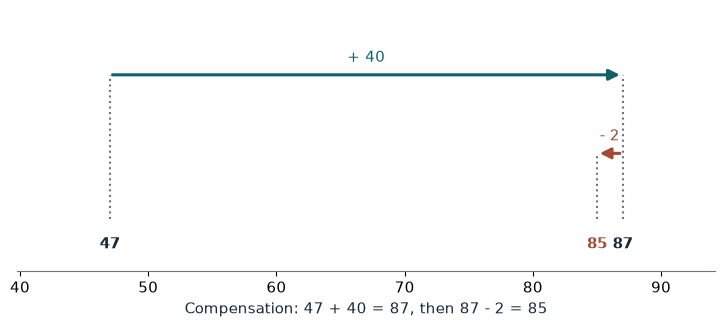

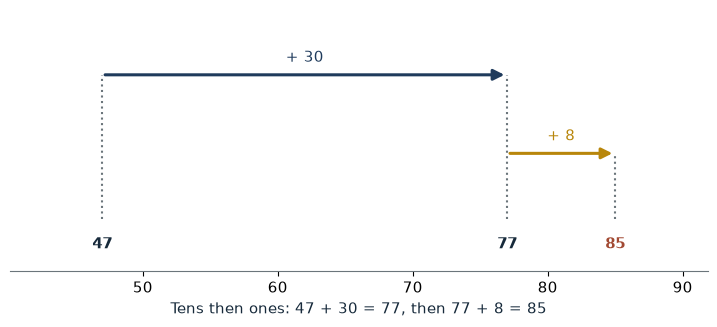

In [10]:
def number_line(ax, start, jumps, colors):
    """jumps: list of (amount, label). Draws stepped arrows and returns the points visited."""
    pts = [start]
    for d, _ in jumps:
        pts.append(pts[-1] + d)
    heights = [2.2, 1.0]
    for i, ((d, label), col) in enumerate(zip(jumps, colors)):
        ax.annotate("", xy=(pts[i + 1], heights[i]), xytext=(pts[i], heights[i]),
                    arrowprops=dict(arrowstyle="-|>", color=col, linewidth=2.2, mutation_scale=16))
        ax.text((pts[i] + pts[i + 1]) / 2, heights[i] + 0.2, label, ha="center", color=col)
        ax.plot([pts[i + 1]] * 2, [0, heights[i]], color=GREY, linestyle="dotted")
    ax.plot([pts[0]] * 2, [0, heights[0]], color=GREY, linestyle="dotted")
    lo, hi = min(pts), max(pts); pad = max(6, (hi - lo) * 0.18)
    for i, p in enumerate(pts):
        ax.text(p, -0.45, str(p), ha="center", fontweight="bold", color=RED if i == len(pts) - 1 else INK)
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(-0.8, 3.2)
    ax.set_yticks([])
    for name in ["left", "right", "top"]:
        ax.spines[name].set_visible(False)
    return pts

a, b = 47, 38
bt, bo, up, extra = add_routes(a, b)
fig, ax = plt.subplots(figsize=(9, 3.4))
number_line(ax, a, [(up, f"+ {up}"), (-extra, f"- {extra}")], [TEAL, RED])
ax.set_xlabel(f"Compensation: {a} + {up} = {a + up}, then {a + up} - {extra} = {a + b}")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
number_line(ax, a, [(bt, f"+ {bt}"), (bo, f"+ {bo}")], [NAVY, GOLD])
ax.set_xlabel(f"Tens then ones: {a} + {bt} = {a + bt}, then {a + bt} + {bo} = {a + b}")
plt.show()

**What this shows.** Compensation jumps to a convenient round number, then steps back by the amount it overshot: $47 + 40 = 87$, then $87 - 2 = 85$. The tens-then-ones route makes two forward jumps: $47 + 30 = 77$, then $77 + 8 = 85$. Both stop at 85, so each checks the other. When a number sits just below a round number, add the round number and correct, and say out loud whether you added too much, because that decides the sign of the correction.

**Where it stops working.** Here the round number is the next ten above the second number. If you flip the direction of the correction, the answer is off by twice the correction (for example, $47 + 40 + 2 = 89$, which is 4 too high).

## 4. Leave a route back

**The question.** After a subtraction, how can you return to where you started?

**The equations from the chapter.**

$$64 - 27 = 64 - 30 + 3 \qquad\qquad 37 + 27 = 64$$

**What the symbols mean.** $64 - 30 + 3$ removes 30, then restores the extra 3 that was removed. $37 + 27 = 64$ is the *inverse check*: adding back what was taken away rebuilds the start. We start with $64 - 27$ by the tens-then-ones route.

**Try to predict first.** If you subtract 30 from 64 instead, will the correction add or subtract, and by how much?

In [11]:
def sub_routes(a, b):
    bt, bo = (b // 10) * 10, b % 10
    up = (b // 10 + 1) * 10
    return bt, bo, up, up - b

a, b = 64, 27
bt, bo, up, extra = sub_routes(a, b)
d = a - b
print("Route: tens then ones")
print(f"  {a} - {bt} = {a - bt}   (restart note: {a - bt} remains; {bo} still to subtract)")
print(f"  {a - bt} - {bo} = {a - bt - bo}")
print("Route: compensation")
print(f"  {a} - {b} = {a} - {up} + {extra}")
print(f"  {a} - {up} = {a - up}, then {a - up} + {extra} = {a - up + extra}")
print(f"Inverse check: {d} + {b} = {d + b}   (back at {a})")

Route: tens then ones
  64 - 20 = 44   (restart note: 44 remains; 7 still to subtract)
  44 - 7 = 37
Route: compensation
  64 - 27 = 64 - 30 + 3
  64 - 30 = 34, then 34 + 3 = 37
Inverse check: 37 + 27 = 64   (back at 64)


In [12]:
print(f"{'Subtraction':13s}{'Tens then ones':34s}{'Compensation':32s}{'Result':8s}Inverse check")
for a, b in [(64, 27), (72, 36), (91, 47), (120, 68)]:
    bt, bo, up, extra = sub_routes(a, b)
    r1 = f"{a}-{bt}={a-bt}, then -{bo} = {a-bt-bo}"
    r2 = f"{a}-{up}={a-up}, then +{extra} = {a-up+extra}"
    print(f"{a} - {b:<7d}{r1:34s}{r2:32s}{a-b:<8d}{a-b} + {b} = {a-b+b}")

Subtraction  Tens then ones                    Compensation                    Result  Inverse check
64 - 27     64-20=44, then -7 = 37            64-30=34, then +3 = 37          37      37 + 27 = 64
72 - 36     72-30=42, then -6 = 36            72-40=32, then +4 = 36          36      36 + 36 = 72
91 - 47     91-40=51, then -7 = 44            91-50=41, then +3 = 44          44      44 + 47 = 91
120 - 68     120-60=60, then -8 = 52           120-70=50, then +2 = 52         52      52 + 68 = 120


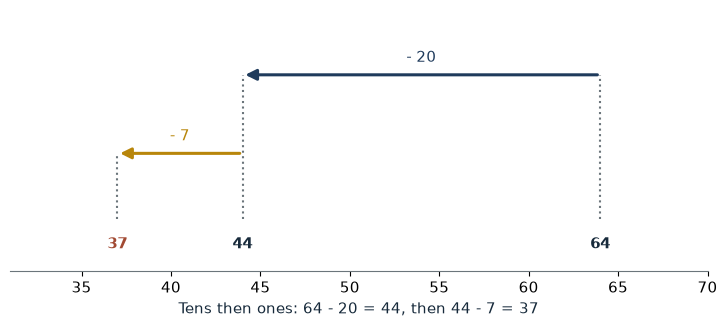

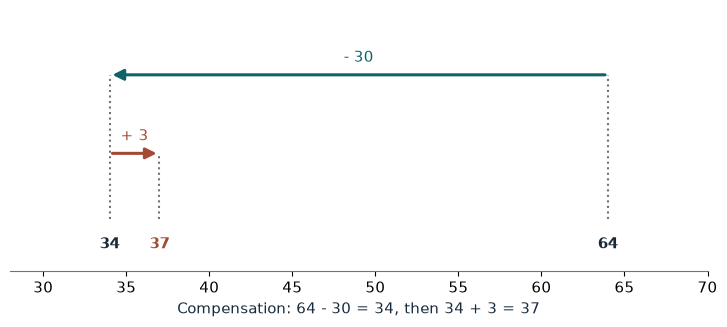

In [13]:
a, b = 64, 27
bt, bo, up, extra = sub_routes(a, b)
fig, ax = plt.subplots(figsize=(9, 3.4))
number_line(ax, a, [(-bt, f"- {bt}"), (-bo, f"- {bo}")], [NAVY, GOLD])
ax.set_xlabel(f"Tens then ones: {a} - {bt} = {a - bt}, then {a - bt} - {bo} = {a - b}")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
number_line(ax, a, [(-up, f"- {up}"), (extra, f"+ {extra}")], [TEAL, RED])
ax.set_xlabel(f"Compensation: {a} - {up} = {a - up}, then {a - up} + {extra} = {a - b}")
plt.show()

**What this shows.** Both routes remove a total of 27. The tens-then-ones route moves back twice: $64 - 20 = 44$, then $44 - 7 = 37$. Compensation moves back too far ($64 - 30 = 34$), then forward by the extra 3 ($34 + 3 = 37$). The middle stop is a *restart line* you can name, such as "44 remains; subtract 7," so if you get interrupted you can pick up exactly there. Then check by adding back: $37 + 27 = 64$.

**Where it stops working.** These are whole numbers with the first number larger, so the result is not negative. A check that repeats the same route can repeat the same slip; inverse addition comes from a different direction, which is why it catches more.

## Practice

Try each one on paper first.

**1.** In $68 + 17$, what are the tens total, the ones total, and the final sum?

<details><summary>Show answer</summary>

Split by place: $68 = 60 + 8$ and $17 = 10 + 7$.

- Tens: $60 + 10 = 70$
- Ones: $8 + 7 = 15$, which is one ten and five ones
- Record: $70 + 10 + 5 = 85$
</details>

**2.** Using compensation, what is $46 + 37$?

<details><summary>Show answer</summary>

37 is close to 40, and $40 - 37 = 3$.

$46 + 37 = 46 + 40 - 3$

$46 + 40 = 86$, then $86 - 3 = 83$.

Check with tens then ones: $46 + 30 = 76$, then $76 + 7 = 83$. Same answer.
</details>

**3.** Using compensation, what is $83 - 29$, and how do you check it?

<details><summary>Show answer</summary>

29 is close to 30, and $30 - 29 = 1$.

$83 - 29 = 83 - 30 + 1$

$83 - 30 = 53$, then $53 + 1 = 54$.

Check by adding back: $54 + 29 = 83$. It returns to the start.
</details>